In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [40]:
!pip install plotly
!pip install cufflinks

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [41]:
import plotly 
import cufflinks as cf
cf.go_offline()
cf.set_config_file(theme='pearl')
sage_forest = [
    "#315C48",
    "#527A63",
    "#8FAF9D",
    "#B8CDBD",
    "#DCE8DF"
]

In [42]:
df_clean = pd.read_csv('../Dataset/cleaned_retail.csv')

df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M')

In [43]:
country_revenue = (
    df_clean.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

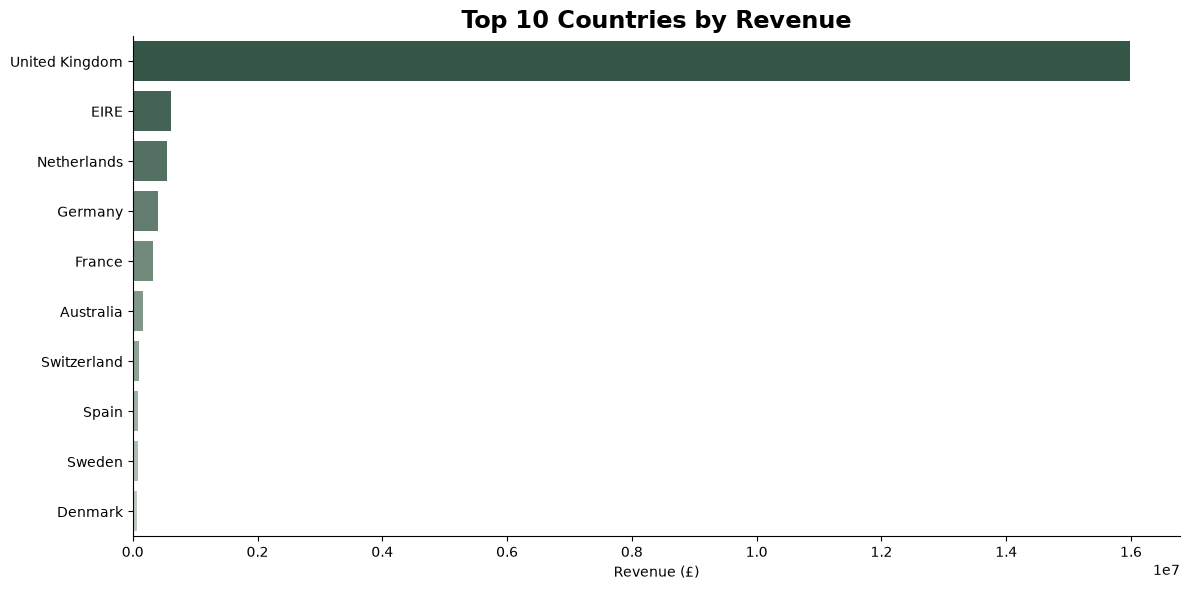

In [44]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=country_revenue.values,
    y=country_revenue.index,
    hue=country_revenue.index,
    palette=sns.color_palette(
        "blend:#315C48,#B8CDBD",
        n_colors=10
    ),
    legend=False
)

plt.title(
    'Top 10 Countries by Revenue',
    fontsize=17,
    fontweight='bold',
    color='#000000'
)

plt.xlabel('Revenue (£)')
plt.ylabel('')

sns.despine()
plt.tight_layout()
plt.show()

In [45]:
product_revenue = (
    df_clean.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

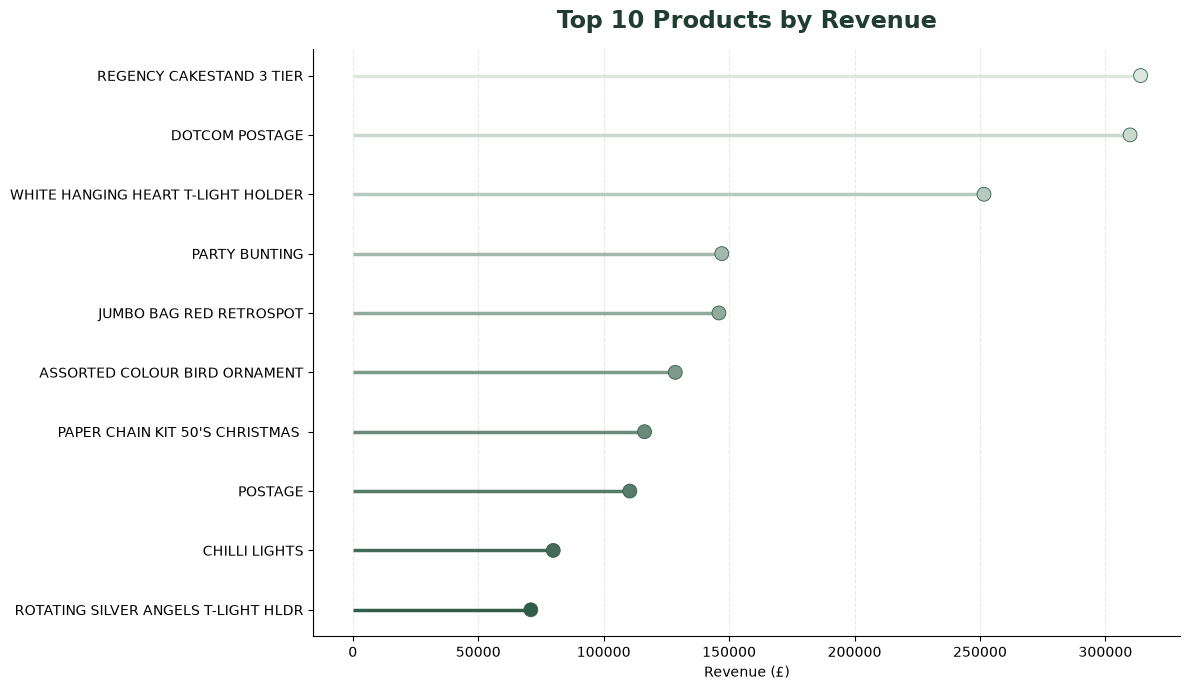

In [46]:
plt.figure(figsize=(12, 7))

colors = sns.color_palette(
    "blend:#315C48,#DCE8DF",
    n_colors=len(product_revenue)
)

y_positions = range(len(product_revenue))

# Stems
for y, value, color in zip(
    y_positions,
    product_revenue.values[::-1],
    colors
):
    plt.hlines(
        y=y,
        xmin=0,
        xmax=value,
        color=color,
        linewidth=2.5
    )

# Dots
plt.scatter(
    product_revenue.values[::-1],
    y_positions,
    c=colors,
    s=100,
    edgecolors='#315C48',
    linewidths=0.6,
    zorder=3
)

plt.yticks(
    y_positions,
    product_revenue.index[::-1]
)

plt.title(
    'Top 10 Products by Revenue',
    fontsize=17,
    fontweight='bold',
    color='#203D32',
    pad=15
)

plt.xlabel('Revenue (£)')
plt.ylabel('')

plt.grid(axis='x', linestyle='--', alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

> **Data Limitation:** The revenue figures include returns, cancellations, and exceptional transactions. Therefore, the results represent preliminary transaction-level revenue rather than final paid-sales revenue. Interpret product rankings with this limitation in mind.

In [47]:
customer_revenue = (
    df_clean.dropna(subset=['Customer ID'])
    .groupby('Customer ID')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

In [51]:
total_customer_revenue = (
    df_clean.dropna(subset=['Customer ID'])
    ['Revenue'].sum()
)

customer_percentage = (
    customer_revenue / total_customer_revenue
) * 100

cumulative_percentage = customer_percentage.cumsum()

In [54]:
cf.set_config_file(
    theme='white',
    colorscale=['#315C48', '#527A63', '#8FAF9D', '#B8CDBD', '#DCE8DF']
)

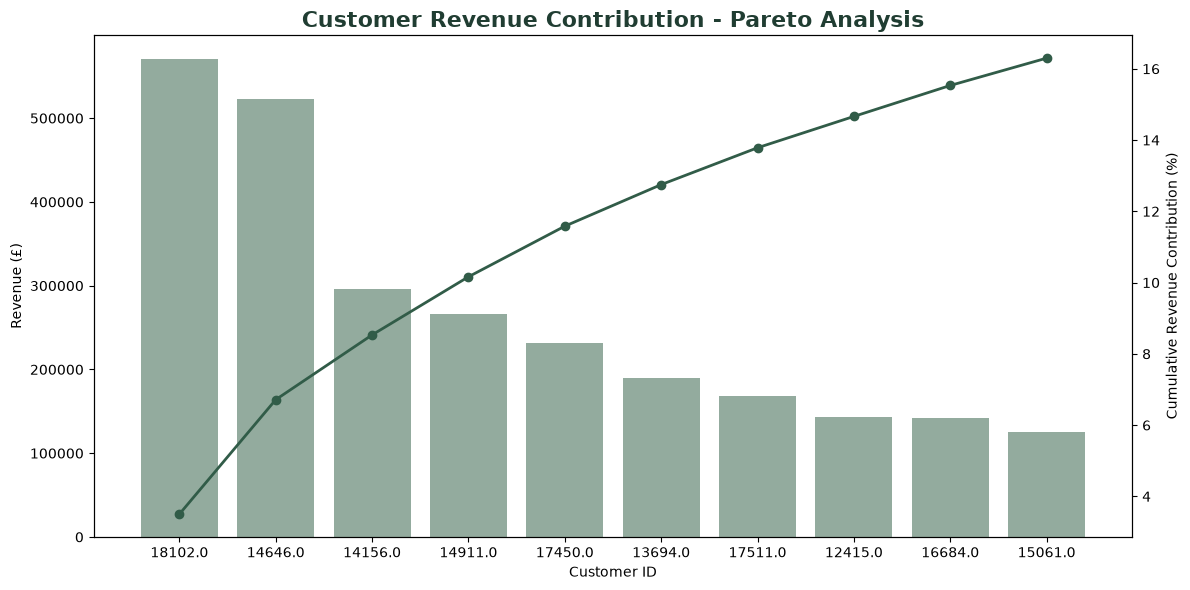

In [58]:
plt.figure(figsize=(12, 6))

# Create the revenue bars
sns.barplot(
    x=customer_revenue.index.astype(str),
    y=customer_revenue.values,
    color='#8FAF9D'
)

plt.xlabel('Customer ID')
plt.ylabel('Revenue (£)')

# Create a second axis for cumulative percentage
plt.twinx()

plt.plot(
    range(len(cumulative_percentage)),
    cumulative_percentage.values,
    color='#315C48',
    marker='o',
    linewidth=2
)

plt.ylabel('Cumulative Revenue Contribution (%)')

plt.title(
    'Customer Revenue Contribution - Pareto Analysis',
    fontsize=16,
    fontweight='bold',
    color='#203D32'
)

plt.tight_layout()
plt.show()

In [56]:
print("Python environment:")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Plotly:", plotly.__version__)
print("Cufflinks:", cf.__version__)

Python environment:
NumPy: 2.5.4
Pandas: 3.1.0
Plotly: 7.1.0
Cufflinks: 0.17.3
